<a href="https://colab.research.google.com/github/ghadahelmy9-bot/bioinformatics-rosalind/blob/main/Module11_Scanpy_Bcell_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%pip install -q "scanpy>=1.11,<1.12" "anndata==0.12.0" "pandas==2.2.3" python-igraph leidenalg pooch

In [4]:
import anndata as ad
import pooch
import scanpy as sc

sc.settings.set_figure_params(dpi=50, facecolor="white")
print("Scanpy loaded successfully")

Scanpy loaded successfully


In [5]:
EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("scverse_tutorials"),
    base_url="doi:10.6084/m9.figshare.22716739.v1/",
)
EXAMPLE_DATA.load_registry_from_doi()

samples = {
    "s1d1": "s1d1_filtered_feature_bc_matrix.h5",
    "s1d3": "s1d3_filtered_feature_bc_matrix.h5",
}

adatas = {}

for sample_id, filename in samples.items():
    path = EXAMPLE_DATA.fetch(filename)
    sample_adata = sc.read_10x_h5(path)
    sample_adata.var_names_make_unique()
    adatas[sample_id] = sample_adata

adata = ad.concat(adatas, label="sample")
adata.obs_names_make_unique()

print(adata.obs["sample"].value_counts())
adata

/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


sample
s1d1    8785
s1d3    8340
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/anndata/_core/anndata.py:1774: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 17125 × 36601
    obs: 'sample'

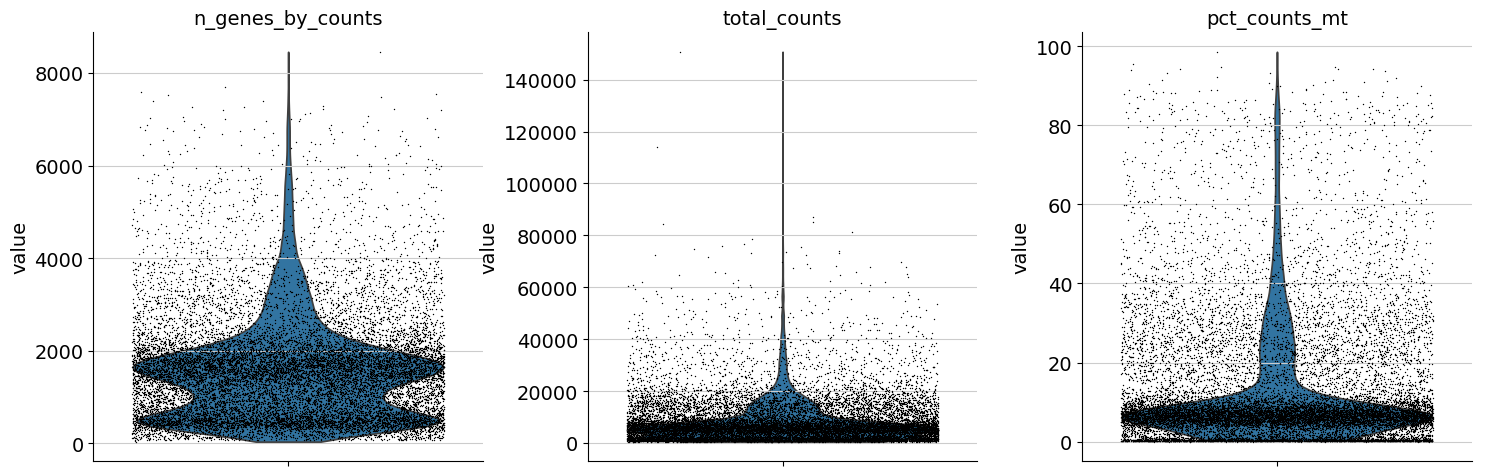

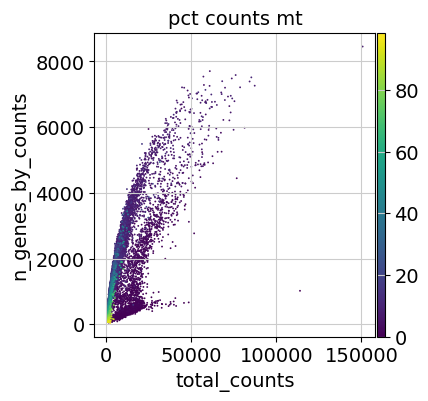

In [6]:
# Identify mitochondrial, ribosomal, and hemoglobin genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

# Calculate quality-control metrics
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt", "ribo", "hb"],
    inplace=True,
    log1p=True,
)

# Plot the QC metrics
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

sc.pl.scatter(
    adata,
    "total_counts",
    "n_genes_by_counts",
    color="pct_counts_mt",
)

In [8]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)

print("After filtering:", adata.shape)

# Detect possible doublets
sc.pp.scrublet(adata, batch_key="sample")

print(adata.obs["predicted_doublet"].value_counts())

After filtering: (17041, 23427)
predicted_doublet
False    16828
True       213
Name: count, dtype: int64


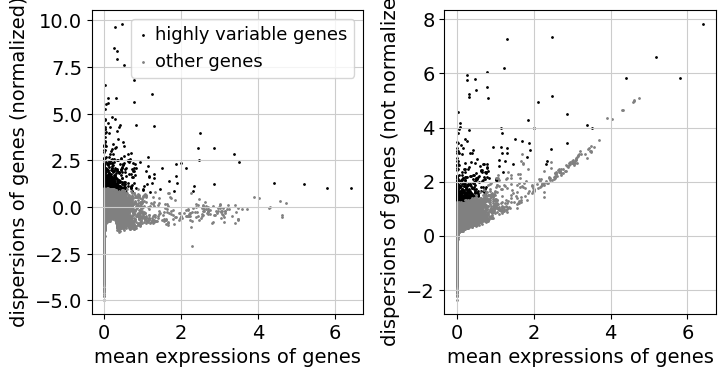

In [9]:
# Save raw counts before normalization
adata.layers["counts"] = adata.X.copy()

# Normalize and log-transform
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

# Identify highly variable genes
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    batch_key="sample",
)

sc.pl.highly_variable_genes(adata)

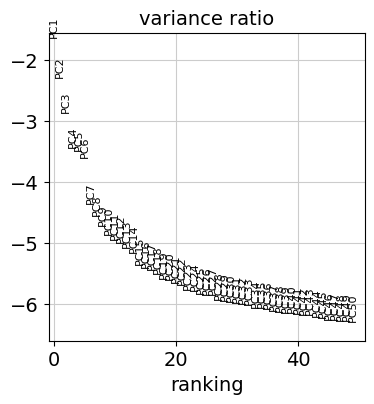

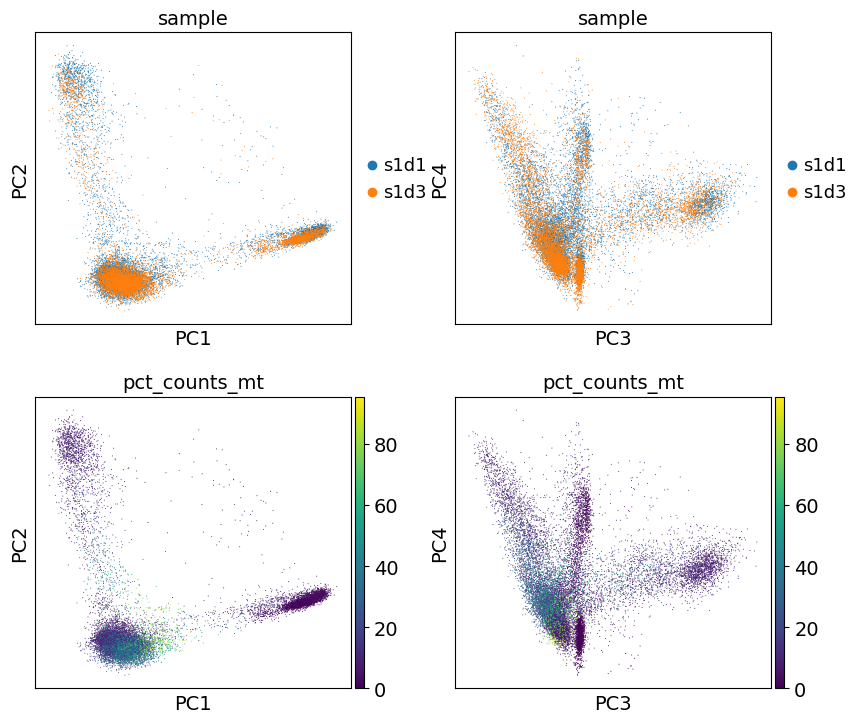

In [10]:
# Run PCA
sc.tl.pca(adata)

# Show variance explained by each principal component
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

# Check patterns related to sample and mitochondrial counts
sc.pl.pca(
    adata,
    color=["sample", "sample", "pct_counts_mt", "pct_counts_mt"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)

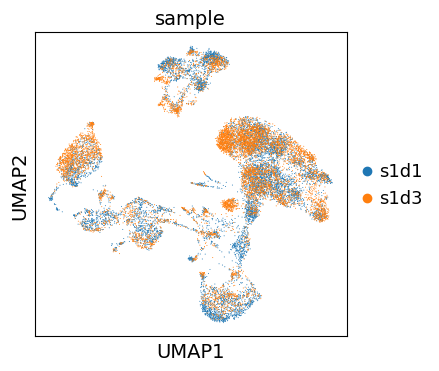

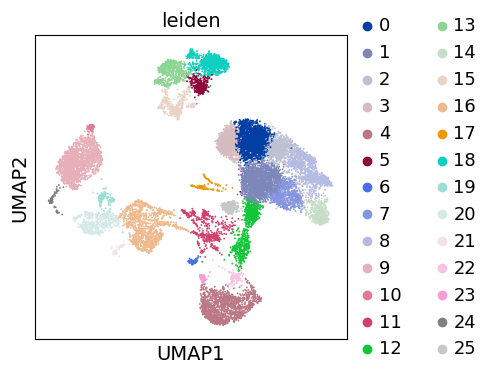

In [11]:
# Build a neighborhood graph using PCA
sc.pp.neighbors(adata)

# Calculate UMAP coordinates
sc.tl.umap(adata)

# Show cells colored by sample
sc.pl.umap(adata, color="sample", size=2)

# Cluster similar cells
sc.tl.leiden(adata, flavor="igraph", n_iterations=2)

# Show the clusters
sc.pl.umap(adata, color="leiden")

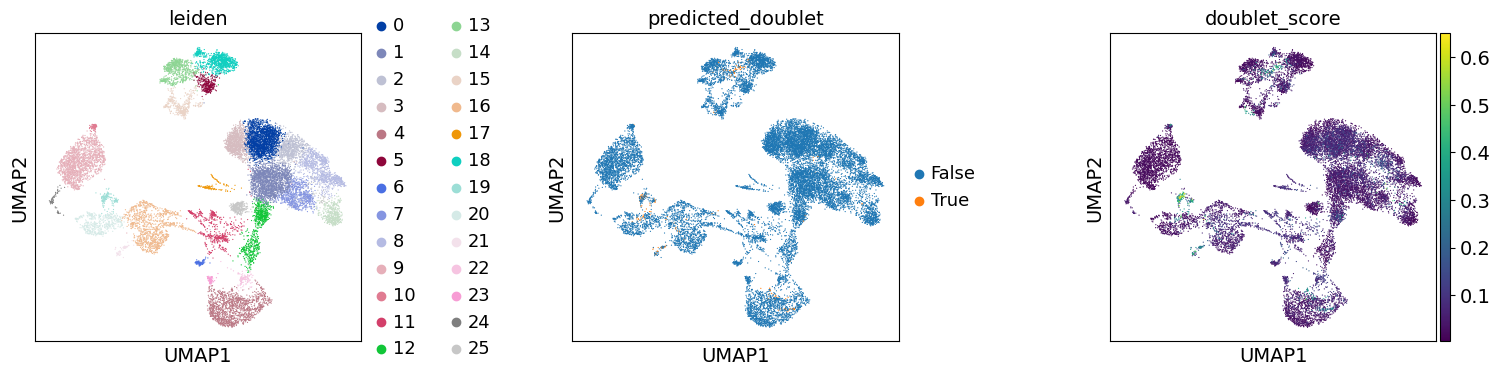

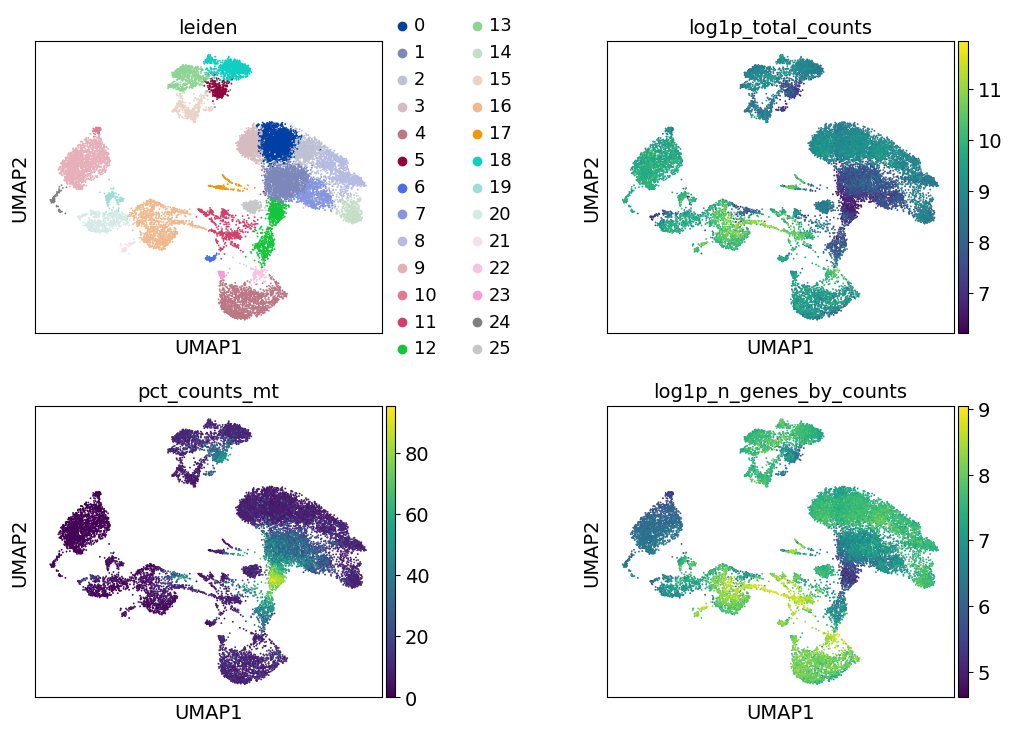

In [12]:
sc.pl.umap(
    adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    wspace=0.5,
    size=3,
)

sc.pl.umap(
    adata,
    color=[
        "leiden",
        "log1p_total_counts",
        "pct_counts_mt",
        "log1p_n_genes_by_counts",
    ],
    wspace=0.5,
    ncols=2,
)

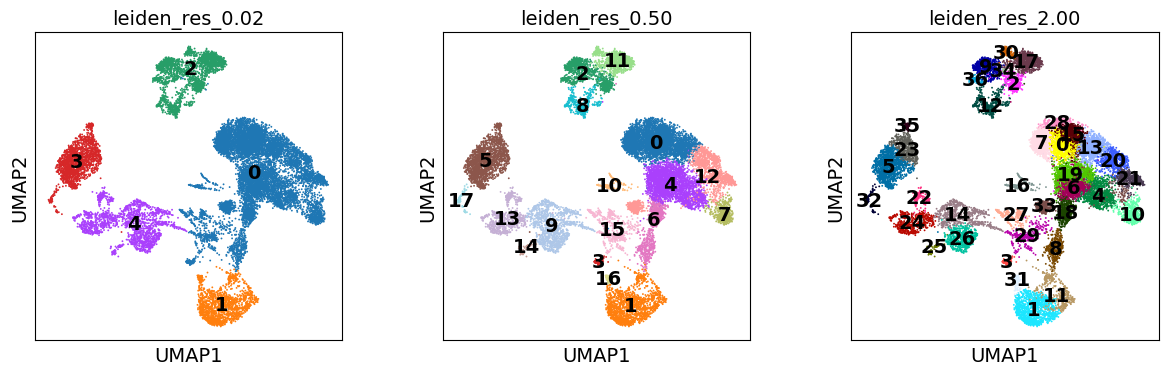

In [13]:
# Compare three clustering resolutions
for res in [0.02, 0.5, 2.0]:
    sc.tl.leiden(
        adata,
        key_added=f"leiden_res_{res:4.2f}",
        resolution=res,
        flavor="igraph",
    )

sc.pl.umap(
    adata,
    color=[
        "leiden_res_0.02",
        "leiden_res_0.50",
        "leiden_res_2.00",
    ],
    legend_loc="on data",
)

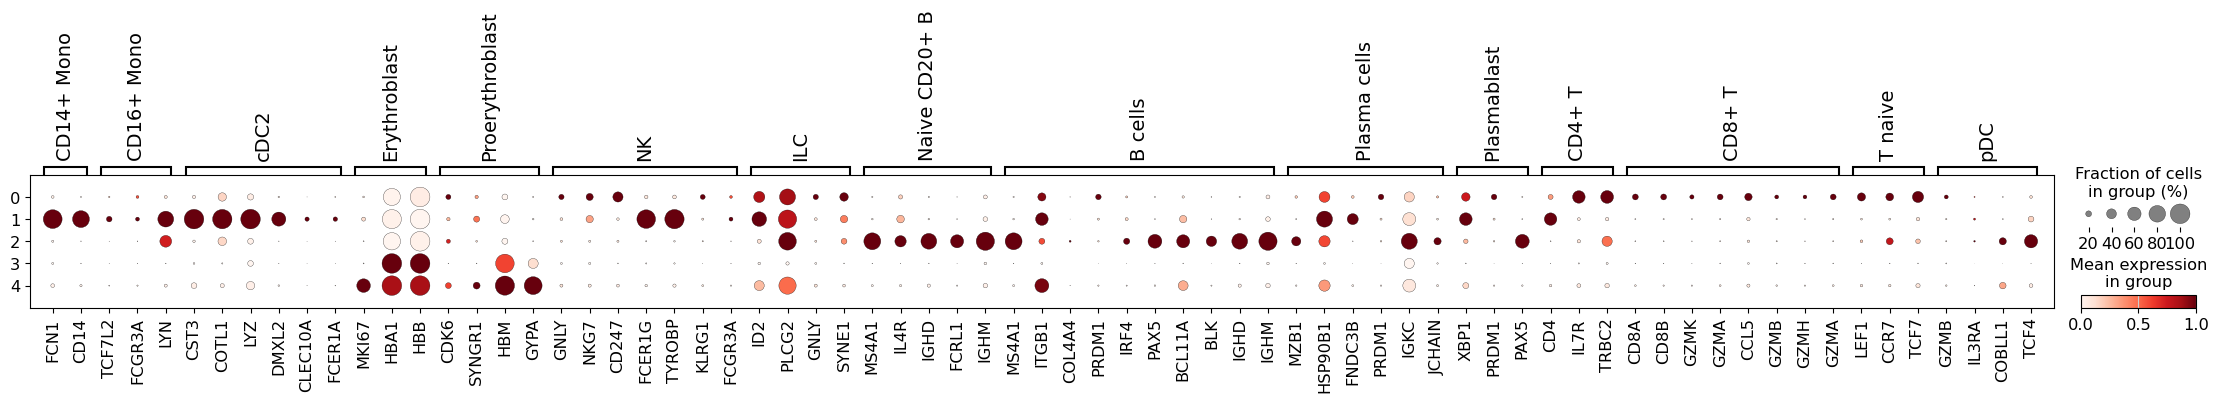

In [14]:
marker_genes = {
    "CD14+ Mono": ["FCN1", "CD14"],
    "CD16+ Mono": ["TCF7L2", "FCGR3A", "LYN"],
    # DMXL2 is a negative marker
    "cDC2": ["CST3", "COTL1", "LYZ", "DMXL2", "CLEC10A", "FCER1A"],
    "Erythroblast": ["MKI67", "HBA1", "HBB"],
    # HBM and GYPA are negative markers
    "Proerythroblast": ["CDK6", "SYNGR1", "HBM", "GYPA"],
    "NK": ["GNLY", "NKG7", "CD247", "FCER1G", "TYROBP", "KLRG1", "FCGR3A"],
    "ILC": ["ID2", "PLCG2", "GNLY", "SYNE1"],
    "Naive CD20+ B": ["MS4A1", "IL4R", "IGHD", "FCRL1", "IGHM"],
    # IGHD and IGHM are negative markers for this group
    "B cells": [
        "MS4A1", "ITGB1", "COL4A4", "PRDM1", "IRF4",
        "PAX5", "BCL11A", "BLK", "IGHD", "IGHM"
    ],
    "Plasma cells": ["MZB1", "HSP90B1", "FNDC3B", "PRDM1", "IGKC", "JCHAIN"],
    # PAX5 is a negative marker
    "Plasmablast": ["XBP1", "PRDM1", "PAX5"],
    "CD4+ T": ["CD4", "IL7R", "TRBC2"],
    "CD8+ T": [
        "CD8A", "CD8B", "GZMK", "GZMA",
        "CCL5", "GZMB", "GZMH", "GZMA"
    ],
    "T naive": ["LEF1", "CCR7", "TCF7"],
    "pDC": ["GZMB", "IL3RA", "COBLL1", "TCF4"],
}

sc.pl.dotplot(
    adata,
    marker_genes,
    groupby="leiden_res_0.02",
    standard_scale="var",
)

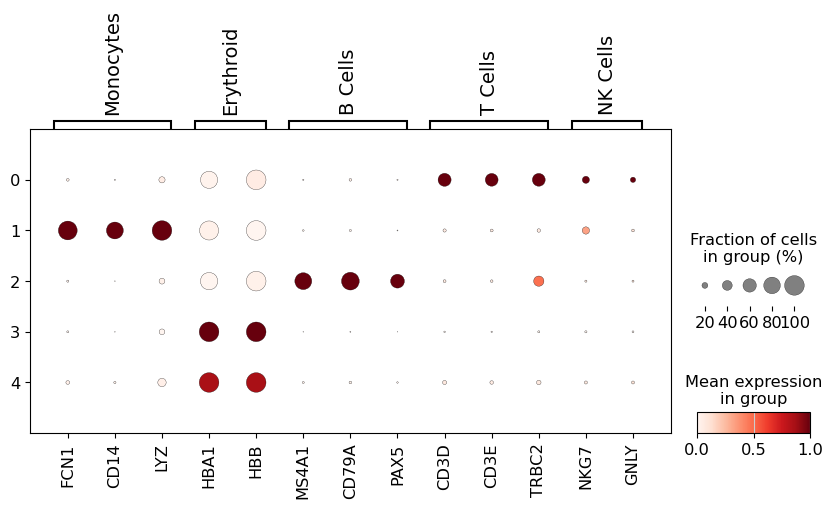

In [15]:
check_markers = {
    "Monocytes": ["FCN1", "CD14", "LYZ"],
    "Erythroid": ["HBA1", "HBB"],
    "B Cells": ["MS4A1", "CD79A", "PAX5"],
    "T Cells": ["CD3D", "CD3E", "TRBC2"],
    "NK Cells": ["NKG7", "GNLY"],
}

sc.pl.dotplot(
    adata,
    check_markers,
    groupby="leiden_res_0.02",
    standard_scale="var",
    figsize=(10, 4),
)

cell_type_lvl1
Lymphocytes    9763
Erythroid      3502
B Cells        2269
Monocytes      1507
Name: count, dtype: int64
Unannotated cells: 0


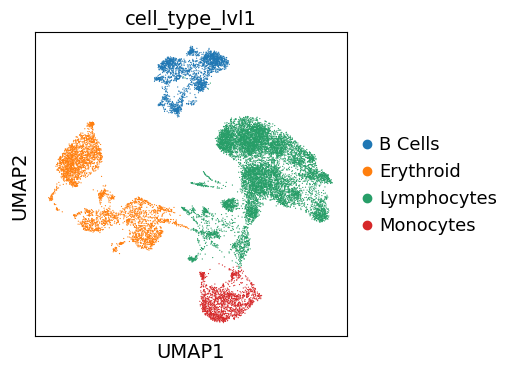

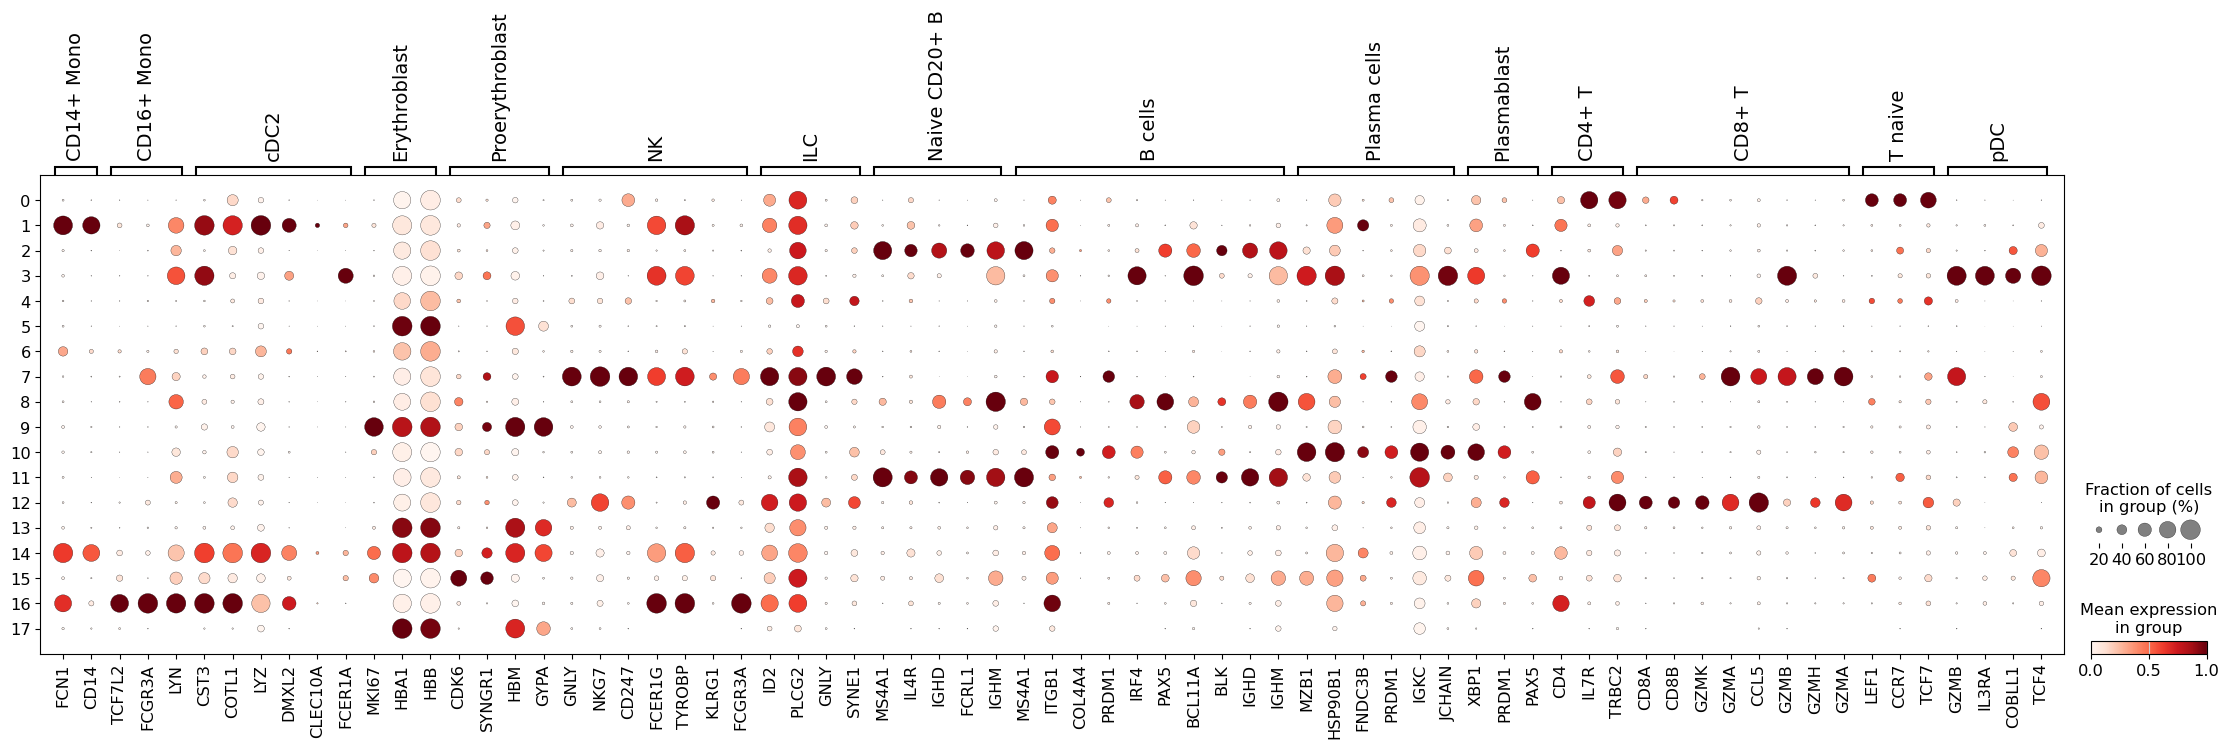

In [16]:
# Assign broad cell-type labels based on marker expression
cell_type_map = {
    "0": "Lymphocytes",
    "1": "Monocytes",
    "2": "B Cells",
    "3": "Erythroid",
    "4": "Erythroid",
}

adata.obs["cell_type_lvl1"] = (
    adata.obs["leiden_res_0.02"]
    .astype(str)
    .map(cell_type_map)
    .astype("category")
)

print(adata.obs["cell_type_lvl1"].value_counts())
print("Unannotated cells:", adata.obs["cell_type_lvl1"].isna().sum())

sc.pl.umap(
    adata,
    color="cell_type_lvl1",
    size=3,
)

sc.pl.dotplot(
    adata,
    marker_genes,
    groupby="leiden_res_0.50",
    standard_scale="var",
)

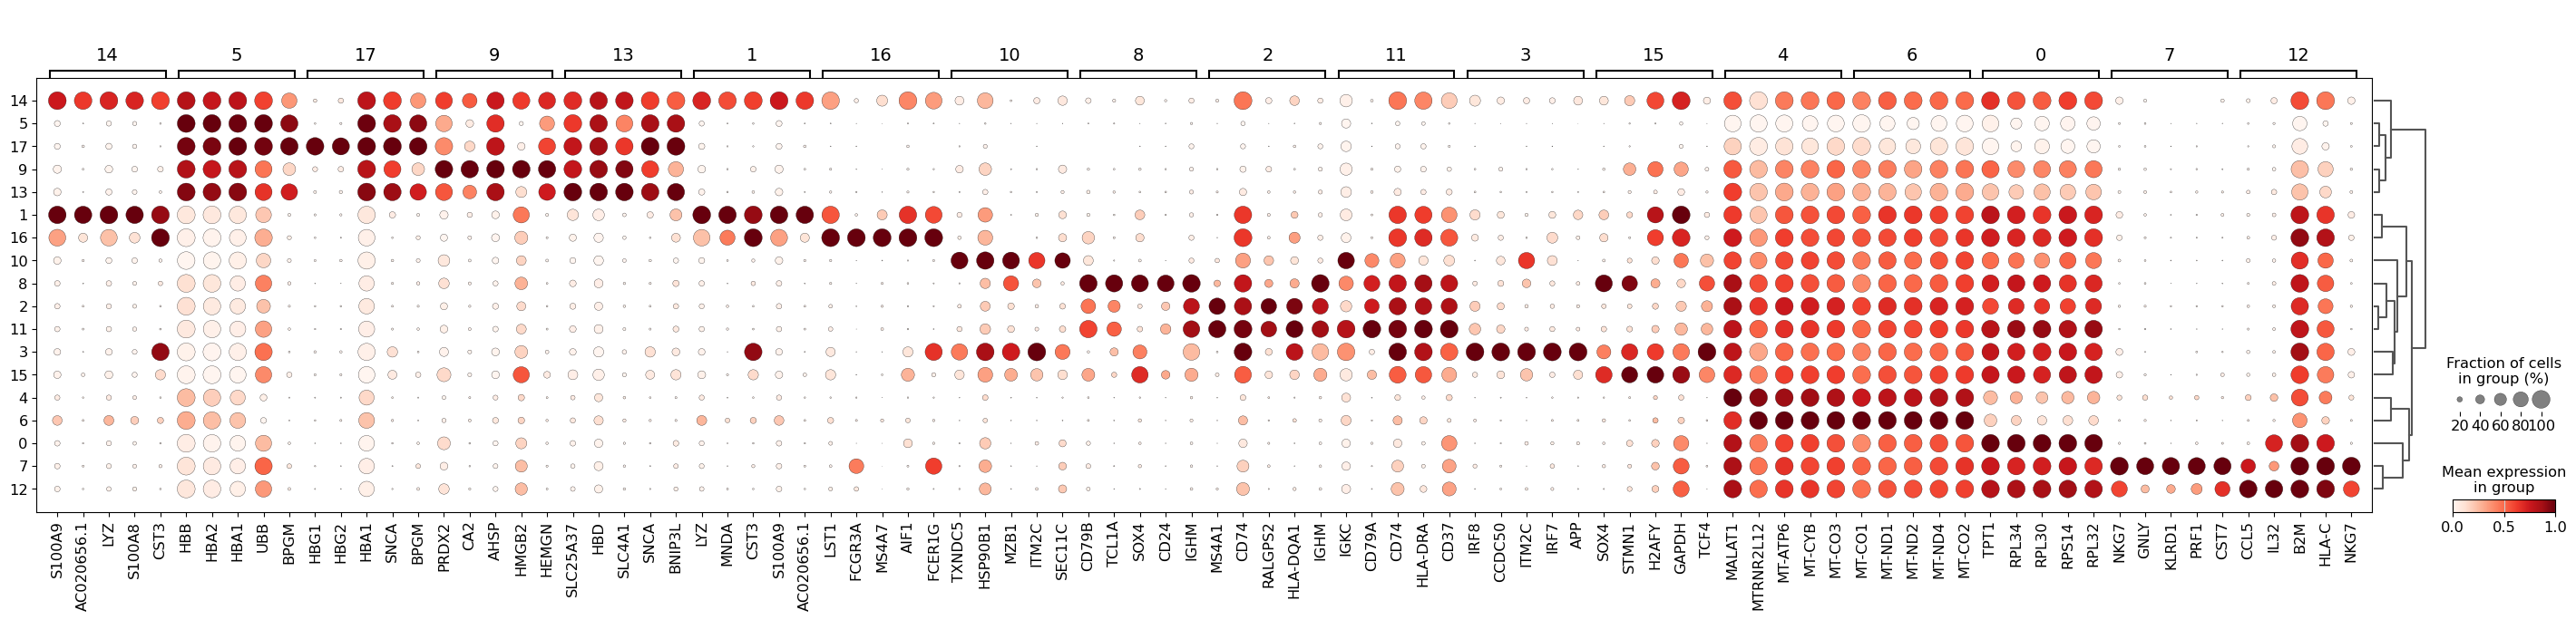

In [17]:
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden_res_0.50",
    method="wilcoxon",
)

sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="leiden_res_0.50",
    standard_scale="var",
    n_genes=5,
)

,names,scores,logfoldchanges,pvals,pvals_adj
0,NKG7,35.537918,6.548978,1.277051e-276,2.991748e-272
1,GNLY,33.851448,7.374753,3.455431e-251,4.047519e-247
2,KLRD1,33.814442,5.832656,1.209767e-250,9.447073e-247
3,PRF1,33.023769,5.431675,3.703158e-239,2.168847e-235
4,CST7,33.007786,5.233107,6.280117e-239,2.942486e-235


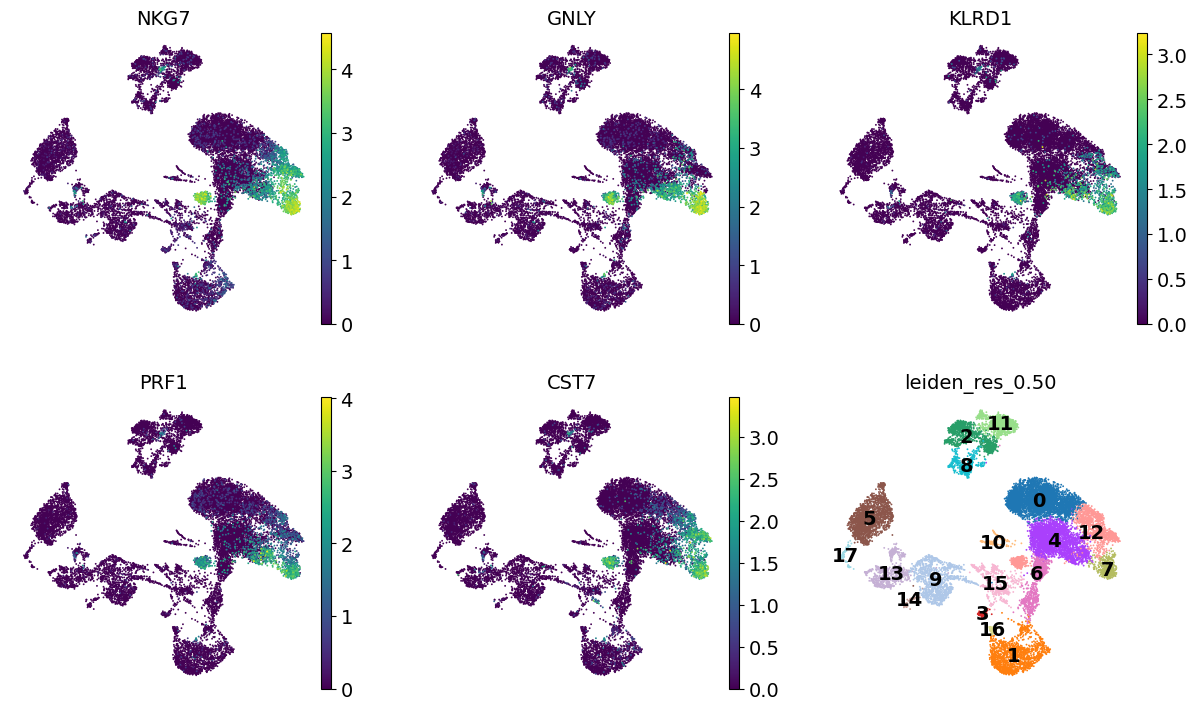

In [18]:
from IPython.display import display

# Display the top 5 marker genes for cluster 7
cluster7_markers = sc.get.rank_genes_groups_df(
    adata,
    group="7",
).head(5)

display(cluster7_markers)

# Plot their expression on UMAP
sc.pl.umap(
    adata,
    color=[*cluster7_markers["names"], "leiden_res_0.50"],
    legend_loc="on data",
    frameon=False,
    ncols=3,
)

## Module 11: B Cells versus Other Annotated Cells

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
    classification_report,
)

SEED = 42
LABEL_COLUMN = "cell_type_lvl1"
POSITIVE_LABEL = "B Cells"
N_GENES = 500
N_JOBS = 2

In [20]:
if LABEL_COLUMN not in adata.obs:
    raise ValueError("Run the tutorial's cell-type annotation cell first.")

if "counts" not in adata.layers:
    raise ValueError("The tutorial's saved counts layer is missing.")

# Exclude cells with missing annotations.
keep = adata.obs[LABEL_COLUMN].notna().to_numpy()
labels = adata.obs.loc[keep, LABEL_COLUMN].astype(str)

if POSITIVE_LABEL not in labels.unique():
    raise ValueError(
        f"{POSITIVE_LABEL!r} was not found. "
        f"Available labels: {sorted(labels.unique())}"
    )

y = (labels == POSITIVE_LABEL).to_numpy(dtype=int)
cell_indices = np.flatnonzero(keep)

# Copy the saved counts into a separate sparse matrix.
X = sparse.csr_matrix(
    adata.layers["counts"][keep], dtype=np.float64
).copy()

if not np.isfinite(X.data).all() or (X.data < 0).any():
    raise ValueError("Expected finite, nonnegative counts.")

if np.any(np.asarray(X.sum(axis=1)).ravel() == 0):
    raise ValueError("Found cells with zero total counts.")

# Each cell is transformed independently using a fixed target.
X = normalize(X, norm="l1", axis=1) * 10_000
X.data = np.log1p(X.data)
X = X.tocsr()

# Reserve 20% for testing.
indices = np.arange(len(y))
trainval_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=y,
    random_state=SEED,
)

# Reserve 25% of the remaining 80% for validation.
train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.25,
    stratify=y[trainval_idx],
    random_state=SEED,
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

if np.bincount(y_train, minlength=2).min() < 5:
    raise ValueError(
        "Five-fold CV requires at least five training cells per class."
    )

summary = pd.DataFrame([
    {
        "Partition": name,
        "Cells": len(target),
        "B Cells": int(target.sum()),
        "Other cells": int((target == 0).sum()),
        "B-cell fraction": target.mean(),
    }
    for name, target in [
        ("Training", y_train),
        ("Validation", y_val),
        ("Test", y_test),
    ]
])

display(summary.round(3))
print("Positive class: B Cells (1)")
print("Negative class: other annotated cells (0)")
print("Expression matrix:", X.shape)

,Partition,Cells,B Cells,Other cells,B-cell fraction
0,Training,10224,1361,8863,0.133
1,Validation,3408,454,2954,0.133
2,Test,3409,454,2955,0.133


Positive class: B Cells (1)
Negative class: other annotated cells (0)
Expression matrix: (17041, 23427)


In [21]:
def make_classifier_pipeline(classifier, scale=False):
    steps = [
        ("remove_constant", VarianceThreshold()),
        ("select_genes", SelectKBest(score_func=f_classif, k=N_GENES)),
    ]

    if scale:
        steps.append(("scale", StandardScaler(with_mean=False)))

    steps.append(("classifier", classifier))
    return Pipeline(steps)


model_specs = {
    "Logistic regression": (
        make_classifier_pipeline(
            LogisticRegression(
                solver="liblinear",
                max_iter=5000,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.01, 0.1, 1.0],
        },
    ),

    "Random forest": (
        make_classifier_pipeline(
            RandomForestClassifier(
                n_estimators=200,
                random_state=SEED,
                n_jobs=1,
            )
        ),
        {
            "classifier__max_depth": [10, None],
            "classifier__min_samples_leaf": [1, 5],
        },
    ),

    "RBF SVM": (
        make_classifier_pipeline(
            SVC(
                kernel="rbf",
                probability=False,
                cache_size=300,
                random_state=SEED,
            ),
            scale=True,
        ),
        {
            "classifier__C": [0.1, 1.0],
            "classifier__gamma": ["scale", 0.001],
        },
    ),
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED,
)

In [22]:
def positive_scores(model, features):
    """Return continuous scores for positive class 1."""
    if hasattr(model, "predict_proba"):
        positive_column = np.flatnonzero(model.classes_ == 1)[0]
        return model.predict_proba(features)[:, positive_column]

    if not np.array_equal(model.classes_, np.array([0, 1])):
        raise ValueError("Expected binary classes [0, 1].")

    return model.decision_function(features)


searches = {}
validation_scores = {}
comparison_rows = []

for name, (pipeline, grid) in model_specs.items():
    print(f"\nRunning five-fold grid search: {name}")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        scoring="average_precision",
        cv=cv,
        refit=True,
        n_jobs=N_JOBS,
        pre_dispatch=N_JOBS,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )

    # Only training data enter grid search.
    search.fit(X_train, y_train)
    searches[name] = search

    scores = positive_scores(search.best_estimator_, X_val)
    validation_scores[name] = scores

    comparison_rows.append({
        "Classifier": name,
        "CV average precision": search.best_score_,
        "CV AP SD": search.cv_results_["std_test_score"][search.best_index_],
        "Validation average precision": average_precision_score(y_val, scores),
        "Validation ROC-AUC": roc_auc_score(y_val, scores),
        "Best parameters": search.best_params_,
    })

comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Classifier")
    .sort_values(
        "Validation average precision",
        ascending=False,
        kind="stable",
    )
)

display(comparison.round(4))

winner_name = comparison.index[0]
winner_model = searches[winner_name].best_estimator_

print(f"\nSelected classifier: {winner_name}")
print("Selection criterion: highest validation average precision")
print("The test set has not been used for model selection.")


Running five-fold grid search: Logistic regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits

Running five-fold grid search: Random forest
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Running five-fold grid search: RBF SVM
Fitting 5 folds for each of 4 candidates, totalling 20 fits


,CV average precision,CV AP SD,Validation average precision,Validation ROC-AUC,Best parameters
Classifier,,,,,
RBF SVM,0.9988,0.0008,0.9986,0.9998,"{'classifier__C': 1.0, 'classifier__gamma': 0...."
Random forest,0.9985,0.0008,0.9977,0.9997,"{'classifier__max_depth': None, 'classifier__m..."
Logistic regression,0.9981,0.0013,0.9972,0.9996,{'classifier__C': 0.1}



Selected classifier: RBF SVM
Selection criterion: highest validation average precision
The test set has not been used for model selection.


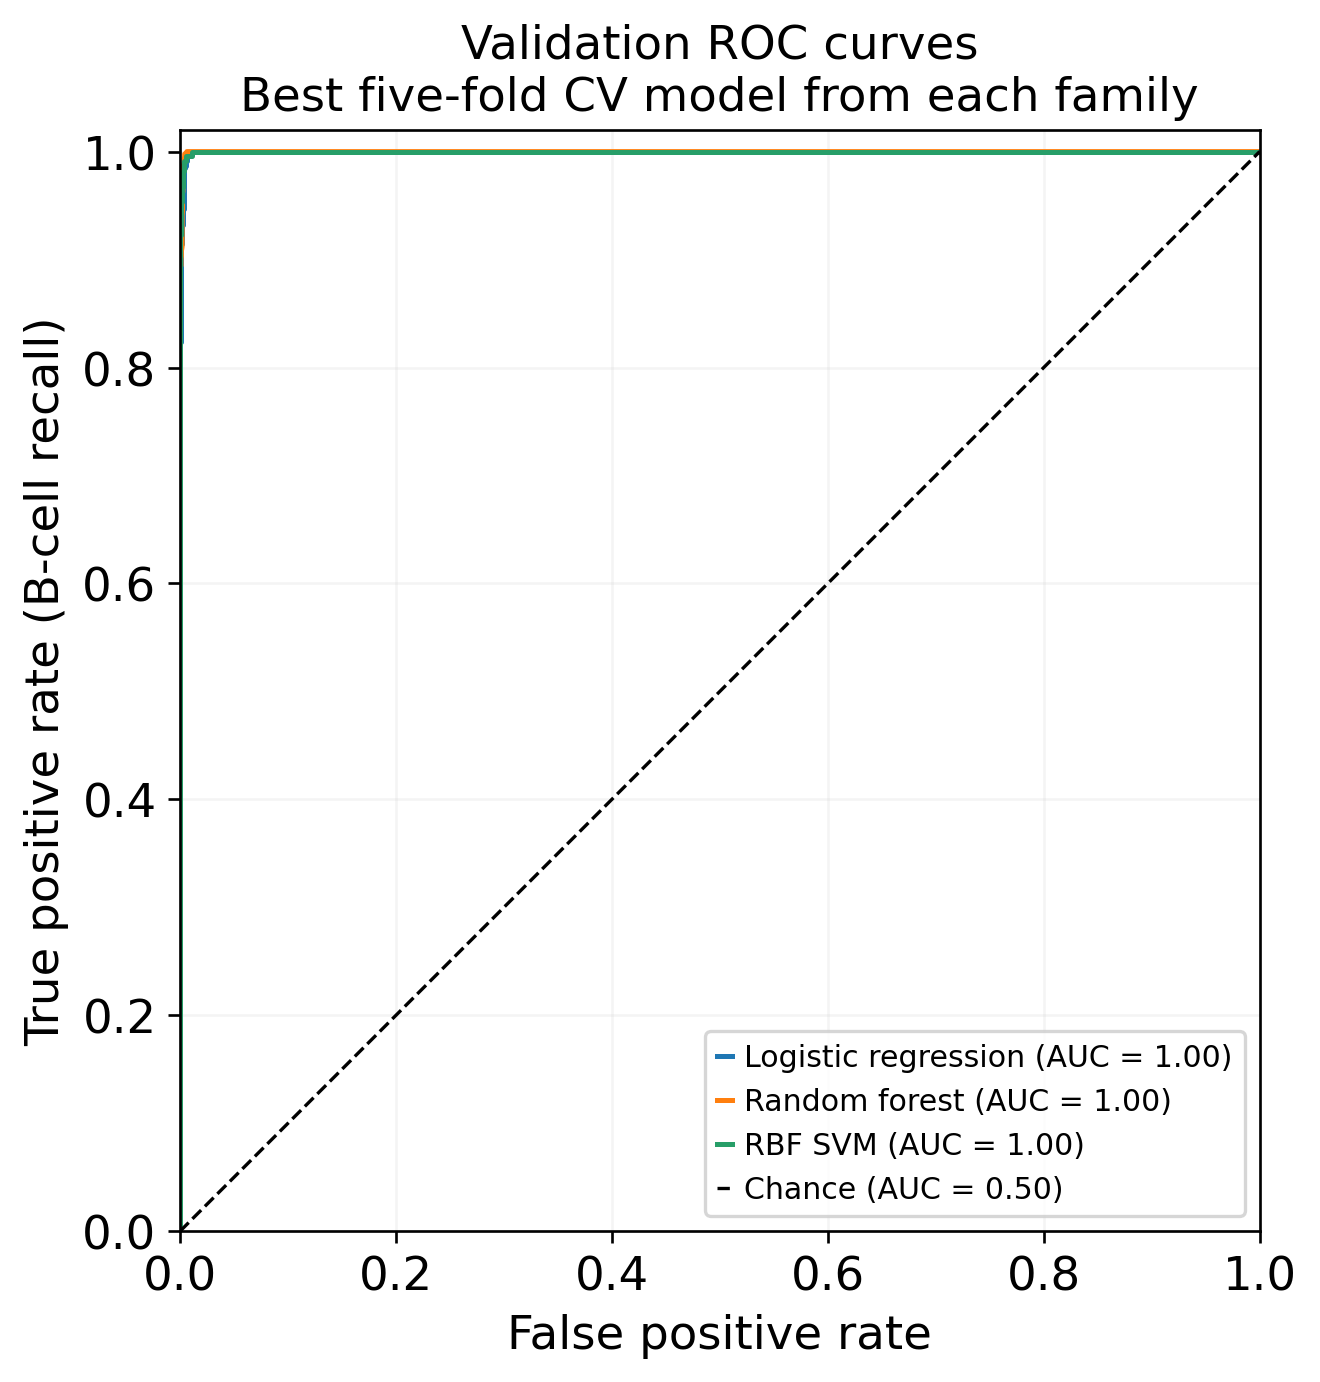

Winner by validation average precision: RBF SVM
ROC-AUC is displayed for comparison; it did not choose the winner.


In [23]:
fig, ax = plt.subplots(figsize=(7, 6), dpi=120)

for name, scores in validation_scores.items():
    RocCurveDisplay.from_predictions(
        y_val,
        scores,
        name=name,
        ax=ax,
    )

ax.plot(
    [0, 1], [0, 1],
    "k--",
    linewidth=1,
    label="Chance (AUC = 0.50)",
)
ax.set(
    title="Validation ROC curves\nBest five-fold CV model from each family",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    f"Winner by validation average precision: {winner_name}\n"
    "ROC-AUC is displayed for comparison; it did not choose the winner."
)

Final test evaluation: RBF SVM
Test average precision: 0.9978
Test ROC-AUC:           0.9997
Test B-cell prevalence: 0.1332

Classification report at the model's default threshold:

                       precision    recall  f1-score   support

Other annotated cells      0.997     0.995     0.996      2955
              B Cells      0.967     0.982     0.975       454

             accuracy                          0.993      3409
            macro avg      0.982     0.989     0.985      3409
         weighted avg      0.993     0.993     0.993      3409



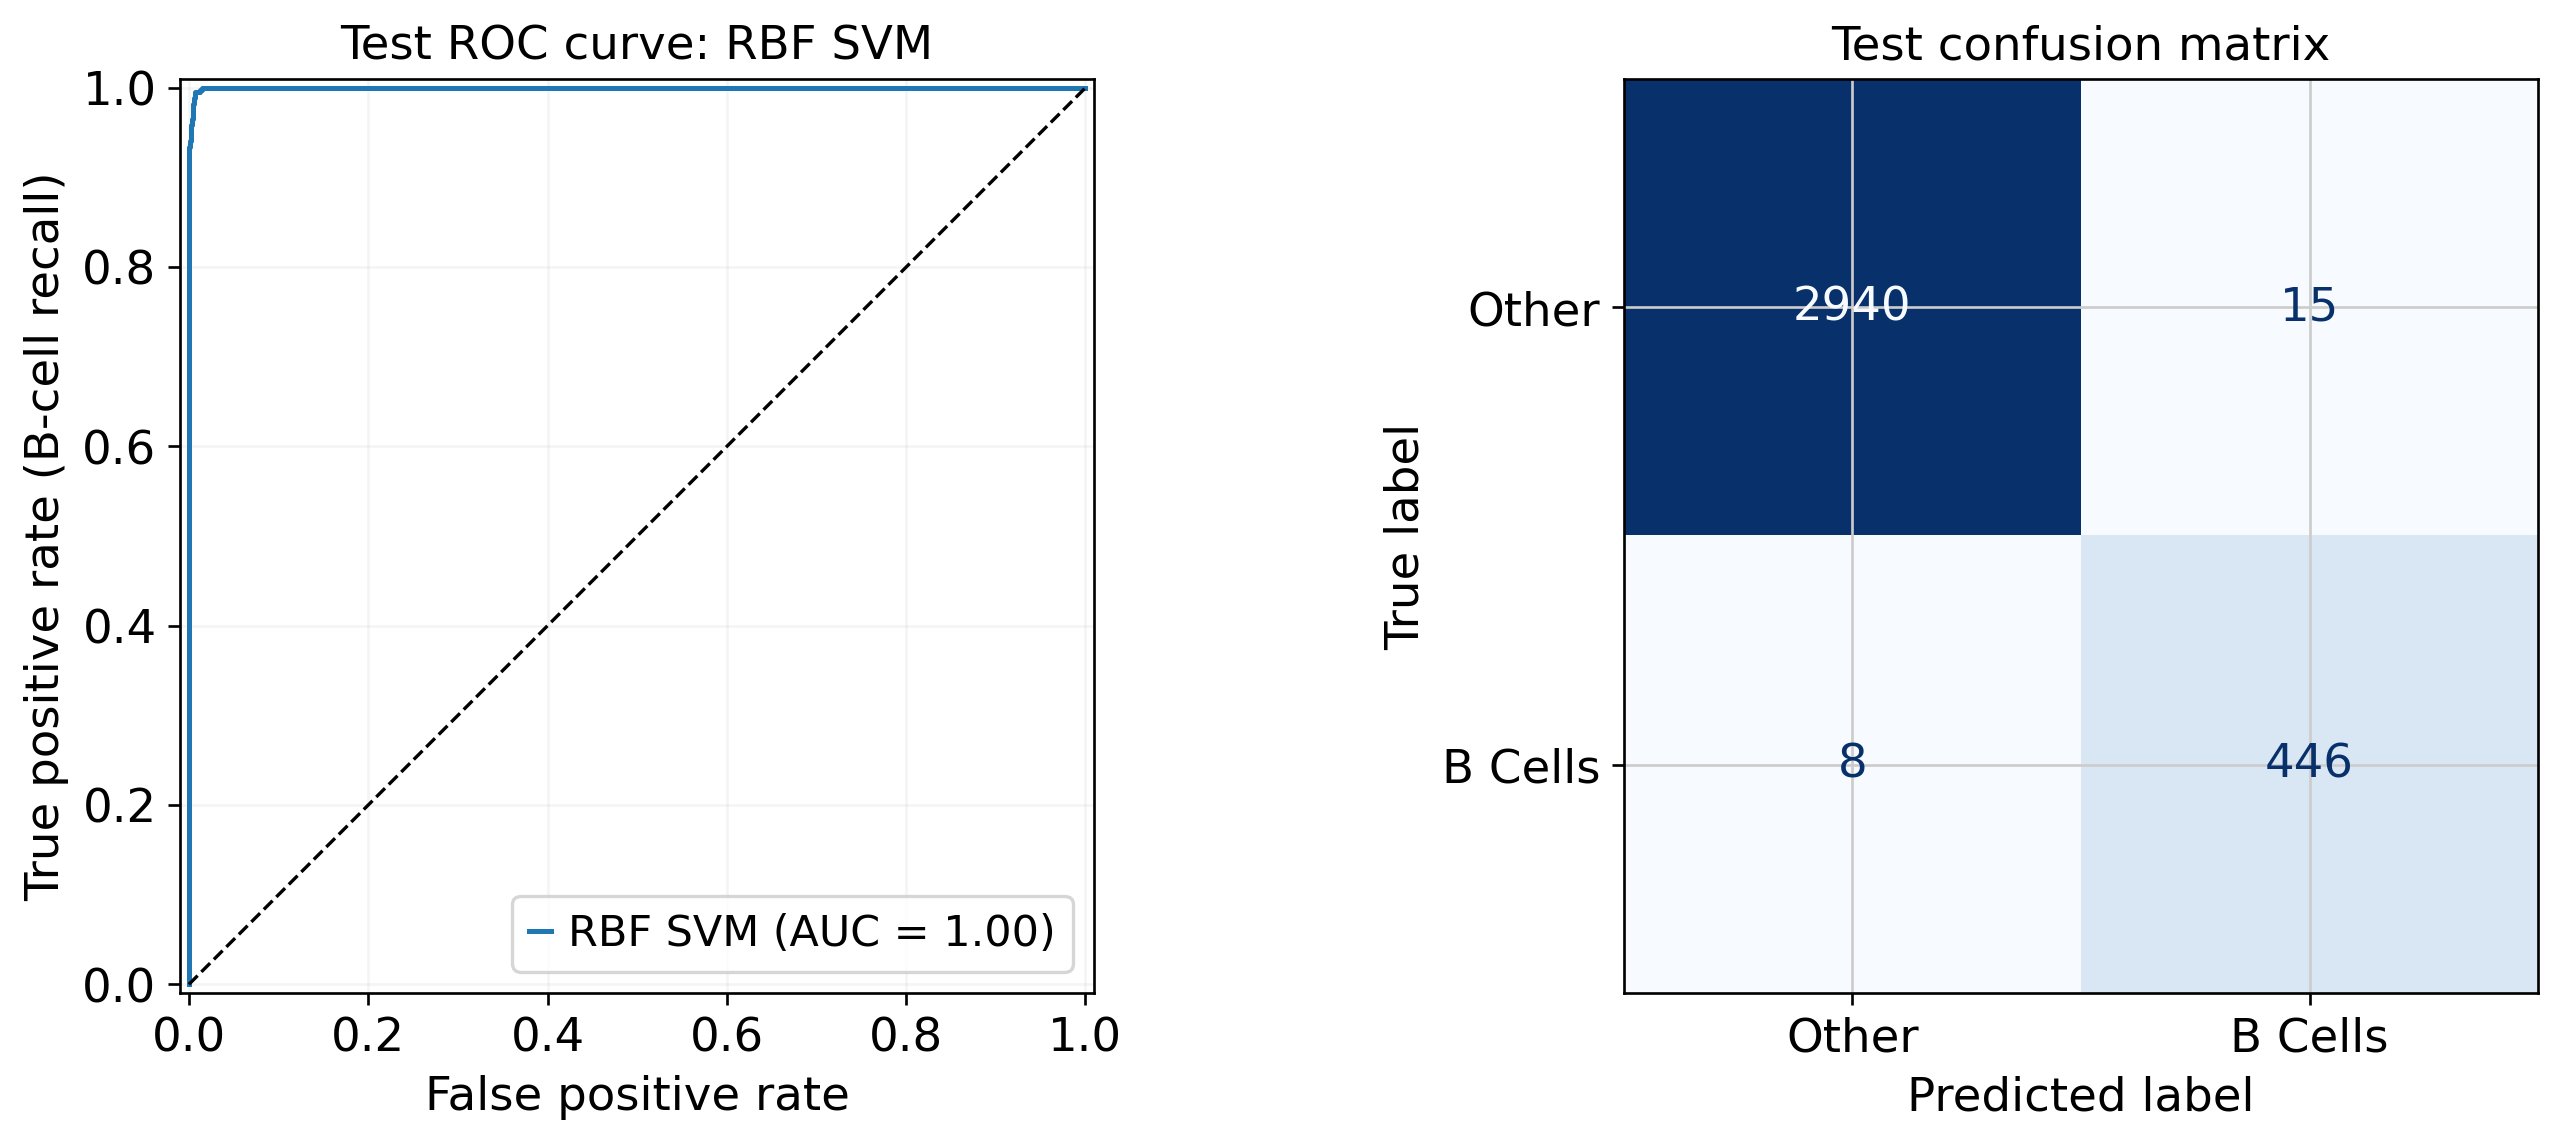

,cell_id,reference_label,predicted_label,positive_class_score,correct
0,ATTCCTAAGTCTGGTT-1,0,0,-3.123282,True
1,CCCGGAAGTCGAAACG-1,0,0,-1.761799,True
2,GTCCTCAGTGCAGGAT-1,0,0,-1.489165,True
3,GCTGAATGTCTTTCTA-1,0,0,-3.174368,True
4,GGGTCACTCGCATAGT-1,0,0,-1.702041,True


In [24]:
test_scores = positive_scores(winner_model, X_test)
test_predictions = winner_model.predict(X_test)

test_ap = average_precision_score(y_test, test_scores)
test_auc = roc_auc_score(y_test, test_scores)

print(f"Final test evaluation: {winner_name}")
print(f"Test average precision: {test_ap:.4f}")
print(f"Test ROC-AUC:           {test_auc:.4f}")
print(f"Test B-cell prevalence: {y_test.mean():.4f}")
print("\nClassification report at the model's default threshold:\n")

print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Other annotated cells", "B Cells"],
    digits=3,
    zero_division=0,
))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)

RocCurveDisplay.from_predictions(
    y_test,
    test_scores,
    name=winner_name,
    ax=axes[0],
)
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set(
    title=f"Test ROC curve: {winner_name}",
    xlabel="False positive rate",
    ylabel="True positive rate (B-cell recall)",
)
axes[0].grid(alpha=0.2)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Other", "B Cells"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[1],
)
axes[1].set_title("Test confusion matrix")

plt.tight_layout()
plt.show()

test_results = pd.DataFrame({
    "cell_id": adata.obs_names[cell_indices[test_idx]].to_numpy(),
    "reference_label": y_test,
    "predicted_label": test_predictions,
    "positive_class_score": test_scores,
})
test_results["correct"] = (
    test_results["reference_label"] == test_results["predicted_label"]
)

display(test_results.head())

In [25]:
from sklearn.metrics import confusion_matrix

print("Selected model:", winner_name)
print("Best hyperparameters:", searches[winner_name].best_params_)

print(f"\nAlways-Other training accuracy: {(y_train == 0).mean():.4%}")
print("Always-Other B-cell recall: 0%")

tn, fp, fn, tp = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
).ravel()

print(f"\nSensitivity: {tp / (tp + fn):.4%}")
print(f"Precision:   {tp / (tp + fp):.4%}")
print(f"Specificity: {tn / (tn + fp):.4%}")
print(f"F1 score:    {2 * tp / (2 * tp + fp + fn):.4f}")

Selected model: RBF SVM
Best hyperparameters: {'classifier__C': 1.0, 'classifier__gamma': 0.001}

Always-Other training accuracy: 86.6882%
Always-Other B-cell recall: 0%

Sensitivity: 98.2379%
Precision:   96.7462%
Specificity: 99.4924%
F1 score:    0.9749


## Exit questions

### 1. Define the classification problem
What are the observations, predictor features, and target labels in this classification problem?

**Your response:** Each observation is one annotated cell. The predictors are normalized and log-transformed gene expression values. The pipeline selects 500 genes within each training fold. The target labels are B Cells (1) and other annotated cells (0).

### 2. Establish a baseline
Using the training partition, calculate the accuracy of a classifier that predicts "Other" for every cell. What would its B-cell recall be? Why stratify the split?

**Your response:** There are 8,863 Other cells out of 10,224 training cells. If the classifier predicts Other for every cell, its accuracy would be 8,863 / 10,224 = 86.69%. However, its B-cell recall would be 0% because it would miss all B Cells. We stratify the split to keep similar proportions of B Cells and Other cells in the training, validation, and test sets.

### 3. Identify the selected model
Which classifier was selected, and what were its best hyperparameters?

**Your response:** The selected model was RBF SVM, with C = 1.0 and gamma = 0.001. These settings were chosen using five-fold cross-validation on the training data. The SVM was then selected because it had the highest validation average precision, which was about 0.9986.

### 4. Interpret what the classifier learned
What did the classifier learn to predict? How does this differ from independently establishing a cell's biological identity?

**Your response:** The classifier learned to predict B Cells versus other annotated cells from gene expression. It learned to match the labels assigned in the tutorial. This does not independently prove the cell's biological identity because these labels also came from gene expression patterns and marker genes. Other evidence, such as protein markers measured by flow cytometry, could help confirm the cell type.

### 5. Interpret classification errors
What would a false positive and a false negative mean in this analysis?

**Your response:** A false positive means that a cell labeled Other was predicted as a B Cell. There were 15 false positives. A false negative means that a cell labeled B Cell was predicted as Other. There were 8 false negatives. These errors are based on comparison with the tutorial's labels.

### 6. Evaluate the classifier
Is the selected classifier a good classifier for this task? Justify your answer using its test-set sensitivity, precision, specificity, and F1 score. Calculate specificity from the confusion matrix as TN / (TN + FP).

**Your response:** Yes, the classifier performed well at predicting the assigned labels in this dataset. Its sensitivity was 446 / (446 + 8) = 98.24%, so it detected most of the labeled B Cells. Its precision was 446 / (446 + 15) = 96.75%, meaning that most cells predicted as B Cells had the B-cell label. Its specificity was TN / (TN + FP) = 2,940 / (2,940 + 15) = 99.49%, so it correctly identified most Other cells. Its F1 score was 0.9749, showing high precision and recall together. However, we still need independent samples to know how well it works on new data.

### 7. Assess independence and leakage
The classifier's gene selection, scaling, and hyperparameter tuning use only training data. However, the tutorial generated the cell-type labels by clustering and annotating the full dataset before the split.

Is the test set fully independent of the complete analysis? Explain how test cells influenced the upstream analysis, what this means for interpreting high test accuracy, and what a stronger evaluation would require.

**Your response:** No, the test set is not fully independent of the whole analysis. Before splitting the data, we used all cells for gene filtering, highly variable gene selection, PCA, the neighborhood graph, clustering, and cell-type annotation. This means that the test cells helped define the groups and labels used later for classification.

The classifier's own gene selection, scaling, and tuning used only training data. However, the labels were already created using the full dataset. Therefore, high test accuracy shows that the model can match these labels well, but it does not independently confirm the biological identity of the cells.

A stronger evaluation would separate entire donors or samples before these analysis steps. We would fit the preprocessing and select the model using only the development data. Then, we would evaluate the fixed model on untouched samples with independently confirmed cell-type labels.